# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 3: Chẩn đoán bệnh tim Heart Disease Cleveland (Mục 5 trang 26 - 27)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Câu a: Nhập dữ liệu đầu vào, tiền xử lý và đổi tên các cột
- Đọc file heart.csv và xóa các dòng dữ liệu trống nếu có.
- Sửa tên 14 cột theo yêu cầu: 'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia', 'target'.

In [2]:
# Câu a: Nhập dữ liệu, tiền xử lý xóa dòng trống và đổi tên cột
heart_path = get_data_path("heart.csv")
df_heart = pd.read_csv(heart_path)

# Xóa các dòng trống nếu có
df_heart = df_heart.dropna()

# Đổi tên 14 cột dữ liệu theo đúng yêu cầu đề bài
new_columns = [
    'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
    'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
    'exercise_induced_angina', 'st_depression', 'st_slope',
    'num_major_vessels', 'thalassemia', 'target'
]
df_heart.columns = new_columns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập dữ liệu sau tiền xử lý: {df_heart.shape}")
print(f"Số lượng giá trị rỗng còn lại: {df_heart.isna().sum().sum()}")
display(df_heart.head())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập dữ liệu sau tiền xử lý: (303, 14)
Số lượng giá trị rỗng còn lại: 0


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
- Tính ma trận hệ số tương quan Pearson giữa 14 thuộc tính.
- Vẽ biểu đồ Heatmap và đánh giá các cặp có độ tương quan cao.

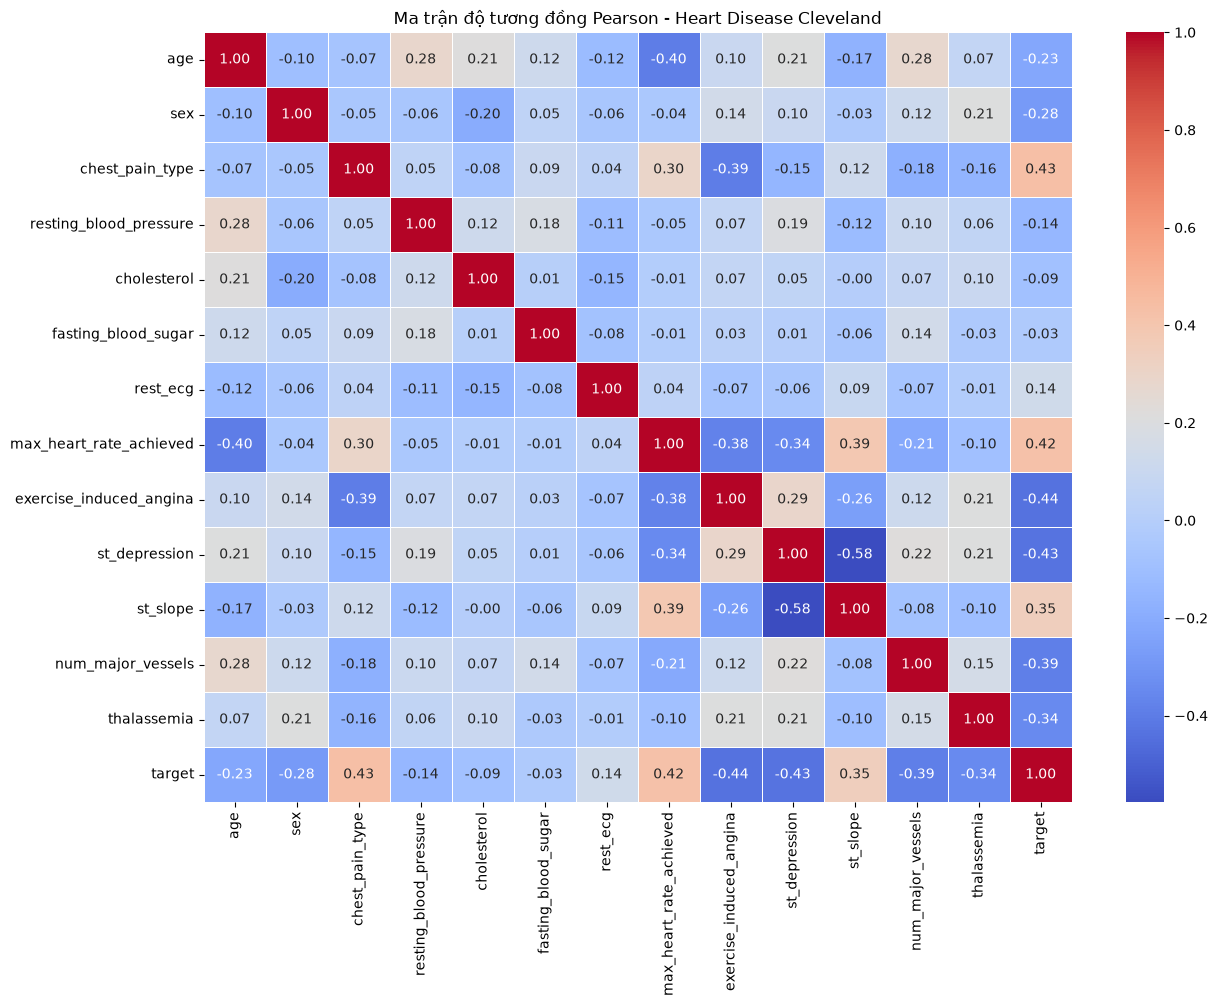

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079

Nhận xét tương quan:
1. Tương quan với biến mục tiêu 'target':
   - 'chest_pain_type' (loại đau ngực) có tương quan dương mạnh nhất với target (r = 0.43).
   - 'max_heart_rate_achieved' (nhịp tim tối đa) có tương quan dương (r = 0.42).
   - 'exercise_induced_angina' (đau ngực khi gắng sức) và 'st_depression' có tương quan âm vừa phải với target (r = -0.44 và r = -0.43).
2. Tương quan giữa các thuộc tính dự đoán độc lập:
   - Hệ số tương quan cao nhất giữa hai biến dự đoán là giữa 'st_slope' và 'st_depression' (r = -0.58).
   - Không có cặp biến dự đoán nào có tương quan vượt ngưỡng loại bỏ (|r| > 0.85). Do đó, giữ nguyên toàn bộ 13 thuộc tính.


In [3]:
# Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
plt.figure(figsize=(14, 10))
corr_heart = df_heart.corr(method='pearson')
sns.heatmap(corr_heart, annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5)
plt.title("Ma trận độ tương đồng Pearson - Heart Disease Cleveland")
plt.show()

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print()
print("Nhận xét tương quan:")
print("1. Tương quan với biến mục tiêu 'target':")
print("   - 'chest_pain_type' (loại đau ngực) có tương quan dương mạnh nhất với target (r = 0.43).")
print("   - 'max_heart_rate_achieved' (nhịp tim tối đa) có tương quan dương (r = 0.42).")
print("   - 'exercise_induced_angina' (đau ngực khi gắng sức) và 'st_depression' có tương quan âm vừa phải với target (r = -0.44 và r = -0.43).")
print("2. Tương quan giữa các thuộc tính dự đoán độc lập:")
print("   - Hệ số tương quan cao nhất giữa hai biến dự đoán là giữa 'st_slope' và 'st_depression' (r = -0.58).")
print("   - Không có cặp biến dự đoán nào có tương quan vượt ngưỡng loại bỏ (|r| > 0.85). Do đó, giữ nguyên toàn bộ 13 thuộc tính.")

### Câu 4: Tách các cột dữ liệu thành hai phần
- Phần 1 (X): Chứa 13 thuộc tính lâm sàng dự đoán (features).
- Phần 2 (y): Chứa thuộc tính quyết định 'target' (0: không bệnh, 1: có bệnh tim).

In [4]:
# Câu 4: Tách các cột dữ liệu thành hai phần
X = df_heart.drop(columns=['target'])
y = df_heart['target']

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập thuộc tính dự đoán (X): {X.shape}")
print(f"Kích thước thuộc tính quyết định (y): {y.shape}")
print(f"Số lượng mẫu không mắc bệnh tim (0): {(y == 0).sum()}")
print(f"Số lượng mẫu có mắc bệnh tim (1): {(y == 1).sum()}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập thuộc tính dự đoán (X): (303, 13)
Kích thước thuộc tính quyết định (y): (303,)
Số lượng mẫu không mắc bệnh tim (0): 138
Số lượng mẫu có mắc bệnh tim (1): 165


### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
- Kiểm tra các thuộc tính có kiểu không phải số.
- Đánh giá khả năng áp dụng mã hóa One-Hot.

In [5]:
# Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
non_numeric_cols = X.select_dtypes(exclude=['number']).columns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Các cột không phải dạng số trong tập Heart Disease: {list(non_numeric_cols)}")
if len(non_numeric_cols) == 0:
    print("Nhận xét: Toàn bộ 13 thuộc tính dự đoán đã được mã hóa sẵn dưới dạng số nguyên (int64) hoặc số thực (float64). Do đó, không cần áp dụng thêm One-Hot Encoding, dữ liệu giữ nguyên để đưa vào mô hình.")
    X_encoded = X.copy()
else:
    X_encoded = pd.get_dummies(X, columns=non_numeric_cols, dtype=int)

print(f"Kích thước tập dữ liệu đặc trưng: {X_encoded.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Các cột không phải dạng số trong tập Heart Disease: []
Nhận xét: Toàn bộ 13 thuộc tính dự đoán đã được mã hóa sẵn dưới dạng số nguyên (int64) hoặc số thực (float64). Do đó, không cần áp dụng thêm One-Hot Encoding, dữ liệu giữ nguyên để đưa vào mô hình.
Kích thước tập dữ liệu đặc trưng: (303, 13)


### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện và kiểm thử
- Sử dụng hàm train_test_split chia dữ liệu thành 70% huấn luyện và 30% kiểm thử với random_state=42:
  `train_test_split(X, y, test_size=0.3, random_state=42)`

In [6]:
# Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện 70% và kiểm thử 30%
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập huấn luyện X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước tập kiểm thử X_test: {X_test.shape}, y_test: {y_test.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập huấn luyện X_train: (212, 13), y_train: (212,)
Kích thước tập kiểm thử X_test: (91, 13), y_test: (91,)


### Câu 7: Xây dựng cây ID3 dựa trên dữ liệu huấn luyện và kiểm thử
- Sử dụng DecisionTreeClassifier với tiêu chí entropy.
- Đánh giá độ chính xác, báo cáo phân lớp và ma trận nhầm lẫn.
- Biểu diễn cấu trúc cây quyết định ID3.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
ID3 Decision Tree Accuracy: 0.6923

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           0       0.64      0.71      0.67        41
           1       0.74      0.68      0.71        50

    accuracy                           0.69        91
   macro avg       0.69      0.69      0.69        91
weighted avg       0.70      0.69      0.69        91



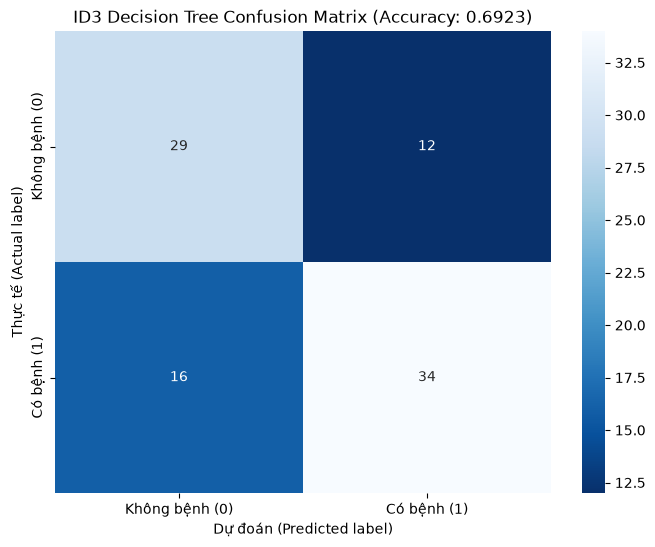

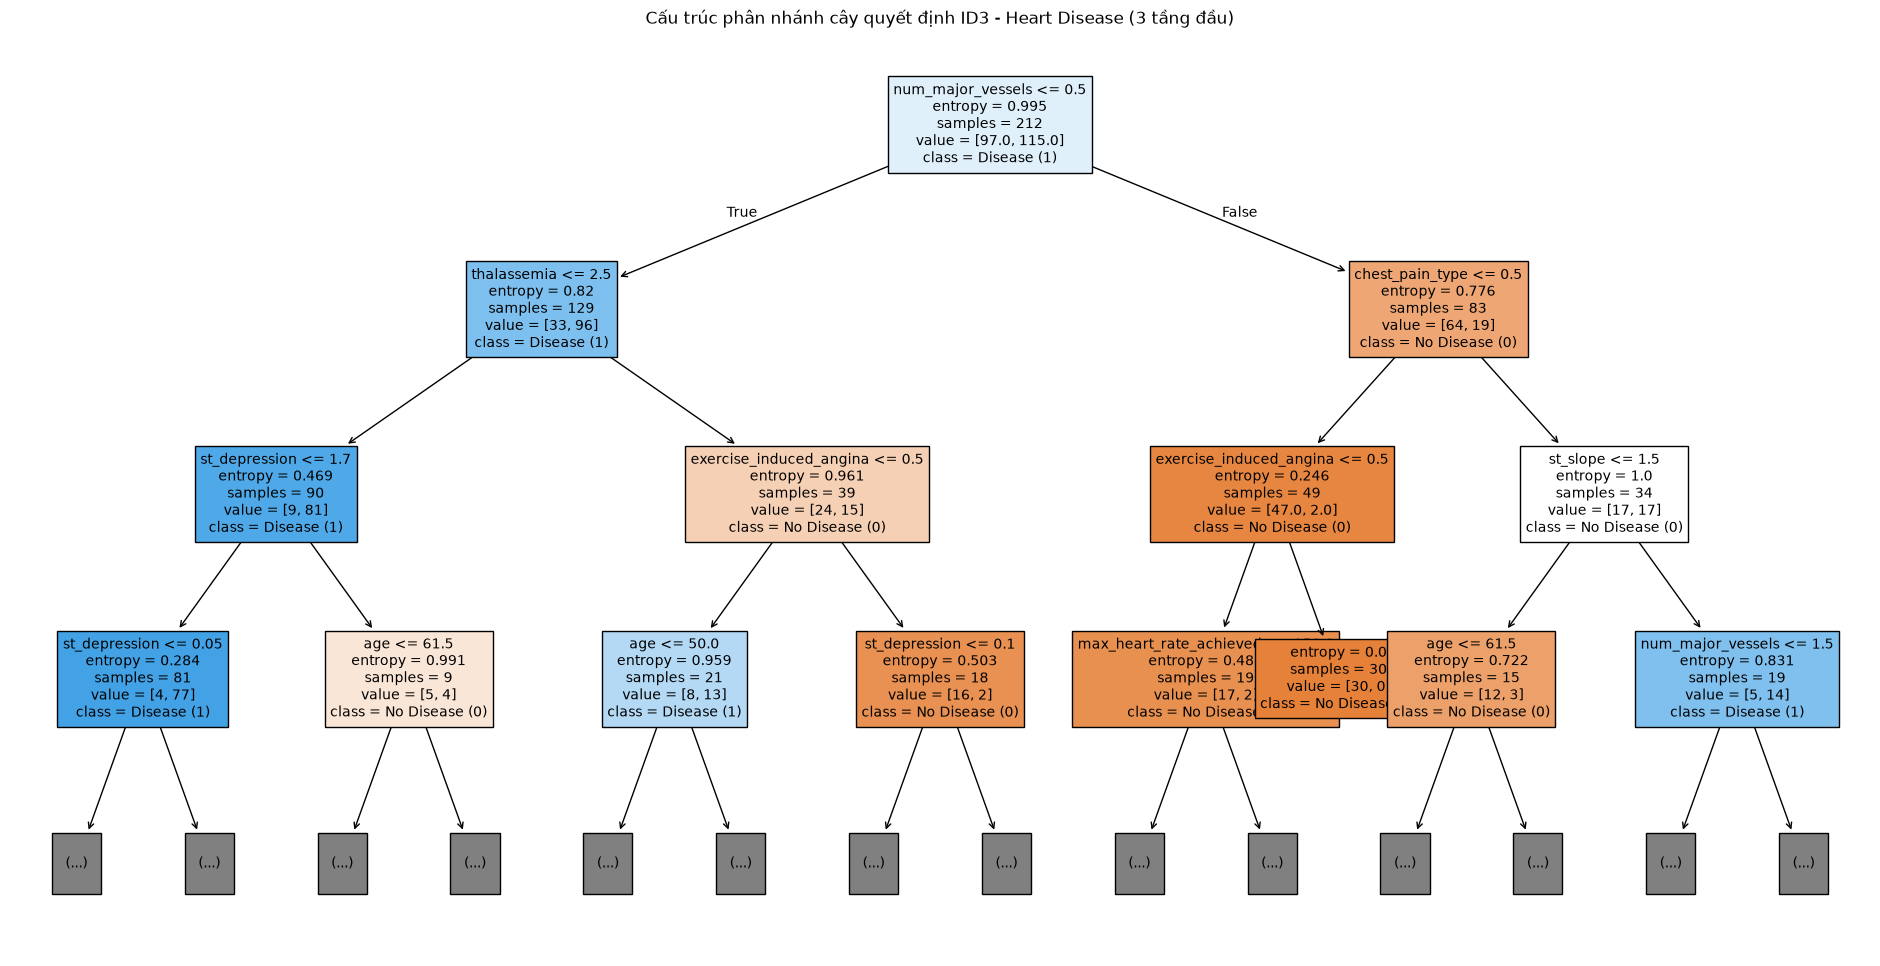

In [7]:
# Câu 7: Xây dựng cây ID3
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_id3.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"ID3 Decision Tree Accuracy: {id3_score:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, id3_pred))

# Ma trận nhầm lẫn
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", cmap="Blues_r",
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'],
            yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
plt.xlabel("Dự đoán (Predicted label)")
plt.ylabel("Thực tế (Actual label)")
plt.title(f"ID3 Decision Tree Confusion Matrix (Accuracy: {id3_score:.4f})")
plt.show()

# Biểu diễn cây quyết định (hiển thị 3 tầng đầu)
plt.figure(figsize=(24, 12))
tree.plot_tree(clf_id3, max_depth=3, feature_names=X.columns.tolist(),
               class_names=['No Disease (0)', 'Disease (1)'], filled=True, fontsize=10)
plt.title("Cấu trúc phân nhánh cây quyết định ID3 - Heart Disease (3 tầng đầu)")
plt.show()

### Câu 8: Xây dựng cây CART dựa trên dữ liệu huấn luyện và kiểm thử
- Sử dụng mô hình DecisionTreeClassifier với tiêu chí gini (Gini Impurity).
- Đánh giá độ chính xác, báo cáo phân lớp và ma trận nhầm lẫn.
- Biểu diễn cấu trúc cây quyết định CART.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
CART Decision Tree Accuracy: 0.7363

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           0       0.68      0.78      0.73        41
           1       0.80      0.70      0.74        50

    accuracy                           0.74        91
   macro avg       0.74      0.74      0.74        91
weighted avg       0.74      0.74      0.74        91



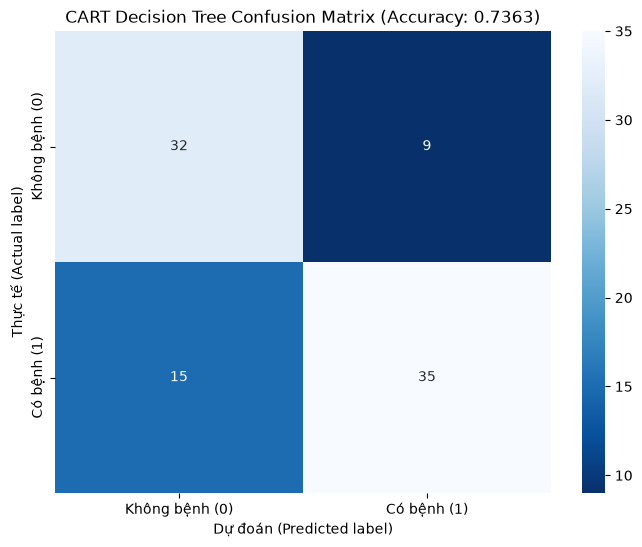

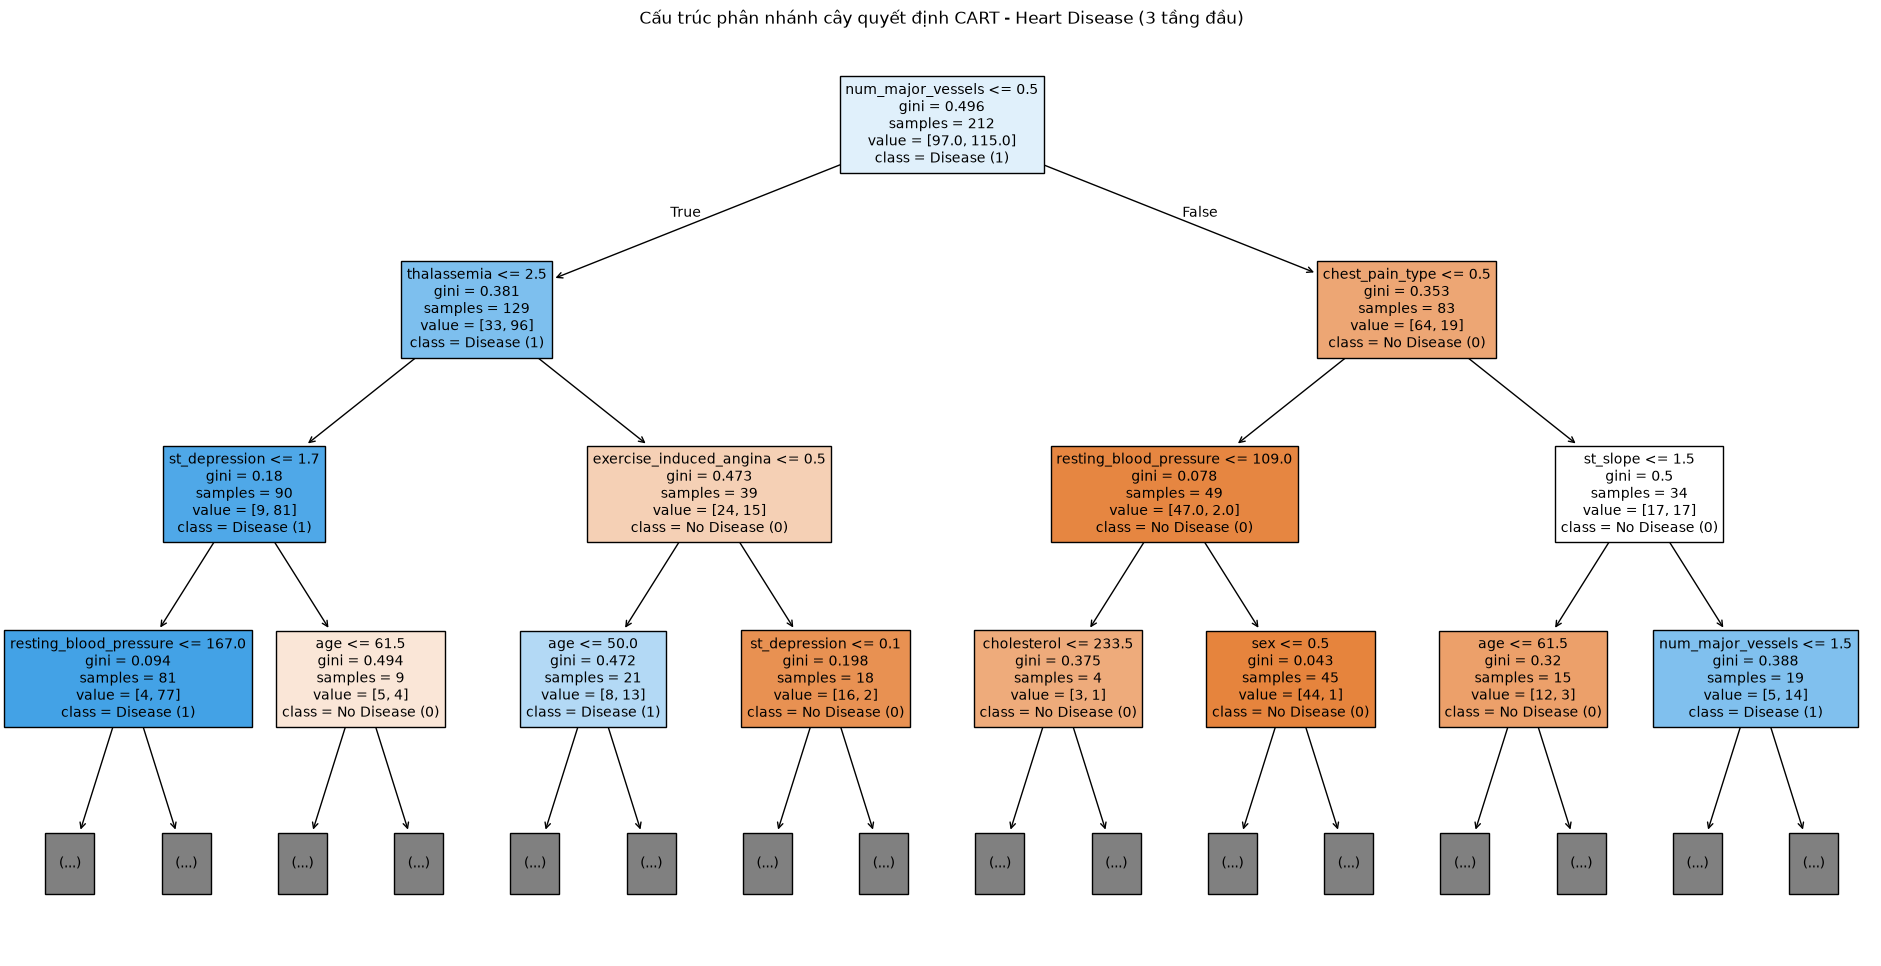

In [8]:
# Câu 8: Xây dựng cây CART
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
clf_cart.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"CART Decision Tree Accuracy: {cart_score:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", cmap="Blues_r",
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'],
            yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
plt.xlabel("Dự đoán (Predicted label)")
plt.ylabel("Thực tế (Actual label)")
plt.title(f"CART Decision Tree Confusion Matrix (Accuracy: {cart_score:.4f})")
plt.show()

# Biểu diễn cây quyết định CART (hiển thị 3 tầng đầu)
plt.figure(figsize=(24, 12))
tree.plot_tree(clf_cart, max_depth=3, feature_names=X.columns.tolist(),
               class_names=['No Disease (0)', 'Disease (1)'], filled=True, fontsize=10)
plt.title("Cấu trúc phân nhánh cây quyết định CART - Heart Disease (3 tầng đầu)")
plt.show()